## TASK 2 · Unemployment Analysis with Python

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
warnings.filterwarnings("ignore")
# Global plot style so every chart looks consistent
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
# India's nationwide lockdown began on 25 March 2020 -> our Pre/Post COVID split point
LOCKDOWN_DATE = pd.Timestamp("2020-03-25")

In [3]:
df=pd.read_csv("Unemployment_Rate_upto_11_2020.csv")

In [4]:
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


In [5]:
print("Shape (rows, columns):", df.shape)
print("\nColumn names (note the stray spaces!):")
print(list(df.columns))
print("\nData types:")
print(df.dtypes)

Shape (rows, columns): (267, 9)

Column names (note the stray spaces!):
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']

Data types:
Region                                       object
 Date                                        object
 Frequency                                   object
 Estimated Unemployment Rate (%)            float64
 Estimated Employed                           int64
 Estimated Labour Participation Rate (%)    float64
Region.1                                     object
longitude                                   float64
latitude                                    float64
dtype: object


In [6]:
print("Null values per column:")
print(df.isnull().sum())
print("\nFully empty rows:", df.isnull().all(axis=1).sum())
print("Duplicate rows:", df.duplicated().sum())

Null values per column:
Region                                      0
 Date                                       0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Region.1                                    0
longitude                                   0
latitude                                    0
dtype: int64

Fully empty rows: 0
Duplicate rows: 0


In [7]:
df.columns = df.columns.str.strip()
df = df.rename(columns={
    "Region": "state",
    "Date": "date",
    "Frequency": "frequency",
    "Estimated Unemployment Rate (%)": "unemployment_rate",
    "Estimated Employed": "employed",
    "Estimated Labour Participation Rate (%)": "labour_participation",
    "Region.1": "macro_region",   # North / South / East / West / Northeast
    "Area": "area",               # present only in some dataset versions (Rural/Urban)
})

# 2) Drop fully empty rows, then strip whitespace in text columns
df = df.dropna(how="all").copy()
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# 3) Type conversion: text -> datetime (dd-mm-yyyy), text -> categorical
df["date"] = pd.to_datetime(df["date"], format="%d-%m-%Y", errors="coerce")
df["frequency"] = df["frequency"].astype("category")
df["state"] = df["state"].astype("category")

# 4) Make sure numeric columns really are numeric
num_cols = ["unemployment_rate", "employed", "labour_participation"]
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")

# 5) Drop any rows where key fields failed to parse, sort by time
df = df.dropna(subset=["state", "date"] + num_cols).sort_values(["state", "date"]).reset_index(drop=True)

# 6) Helper time columns used later
df["month_num"] = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()
df["year_month"] = df["date"].dt.to_period("M")

print("Cleaned shape:", df.shape)
print("Date range:", df["date"].min().date(), "->", df["date"].max().date())
print("Number of states/regions:", df["state"].nunique())
df.info()

Cleaned shape: (267, 12)
Date range: 2020-01-31 -> 2020-10-31
Number of states/regions: 27
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   state                 267 non-null    category      
 1   date                  267 non-null    datetime64[ns]
 2   frequency             267 non-null    category      
 3   unemployment_rate     267 non-null    float64       
 4   employed              267 non-null    int64         
 5   labour_participation  267 non-null    float64       
 6   macro_region          267 non-null    object        
 7   longitude             267 non-null    float64       
 8   latitude              267 non-null    float64       
 9   month_num             267 non-null    int32         
 10  month_name            267 non-null    object        
 11  year_month            267 non-null    period[

## 3. Exploratory Data Analysis

## 3.1 Region-wise average unemployment

In [8]:
state_avg = (
    df.groupby("state", observed=True)[num_cols]
      .mean()
      .sort_values("unemployment_rate", ascending=False)
      .round(2)
)
state_avg

,unemployment_rate,employed,labour_participation
state,,,
Haryana,27.48,6844059.00,42.10
Tripura,25.06,1397291.60,57.85
Jharkhand,19.54,8770642.40,40.36
Bihar,19.47,23606828.00,37.17
Delhi,18.41,4632821.90,35.86
Puducherry,17.94,365262.90,35.92
Jammu & Kashmir,16.48,3310031.67,37.89
Himachal Pradesh,16.07,2033884.90,40.25
Rajasthan,15.87,19731752.20,40.59


,unemployment_rate,employed,labour_participation
macro_region,,,
North,15.89,13072487.92,38.70
East,13.92,19602366.90,40.11
Northeast,10.95,3617105.53,52.06
South,10.45,14040589.33,40.44
West,8.24,18623512.72,41.26


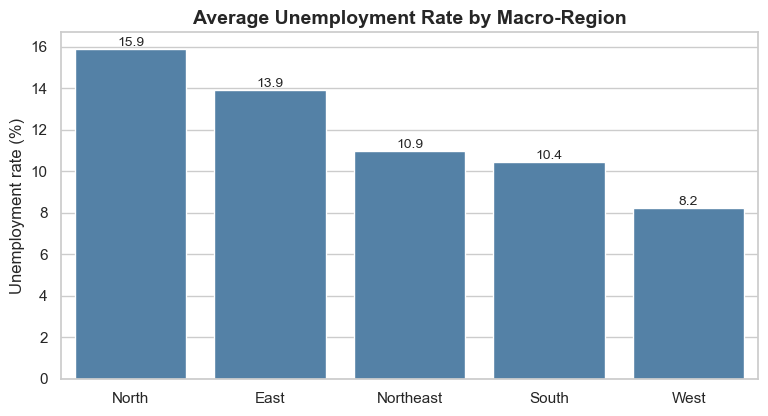

In [9]:
if "macro_region" in df.columns:
    macro_avg = (
        df.groupby("macro_region")[num_cols]
          .mean()
          .sort_values("unemployment_rate", ascending=False)
          .round(2)
    )
    display(macro_avg)

    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.barplot(x=macro_avg.index, y=macro_avg["unemployment_rate"], color="steelblue", ax=ax)
    ax.set_title("Average Unemployment Rate by Macro-Region")
    ax.set_xlabel("")
    ax.set_ylabel("Unemployment rate (%)")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=10)
    plt.show()

## 3.2 Month-wise trends

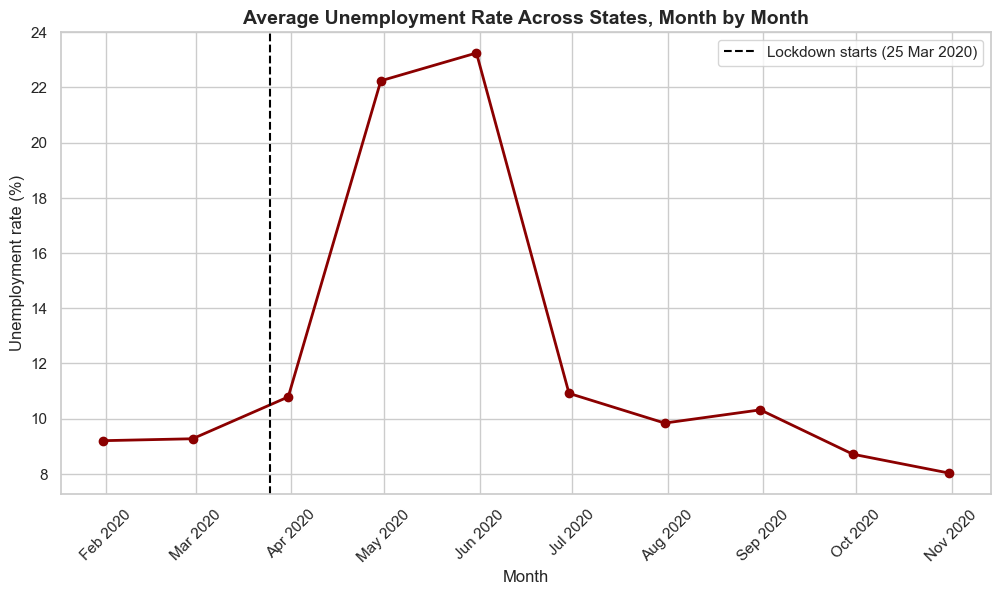

Peak month: May 2020 -> 23.2%
Lowest month: October 2020 -> 8.0%


In [10]:
monthly_national = df.groupby("date")["unemployment_rate"].mean()

fig, ax = plt.subplots()
ax.plot(monthly_national.index, monthly_national.values, marker="o", color="darkred", linewidth=2)
ax.axvline(LOCKDOWN_DATE, color="black", linestyle="--", label="Lockdown starts (25 Mar 2020)")
ax.set_title("Average Unemployment Rate Across States, Month by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Unemployment rate (%)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
ax.legend()
plt.show()

print("Peak month:", monthly_national.idxmax().strftime("%B %Y"),
      f"-> {monthly_national.max():.1f}%")
print("Lowest month:", monthly_national.idxmin().strftime("%B %Y"),
      f"-> {monthly_national.min():.1f}%")

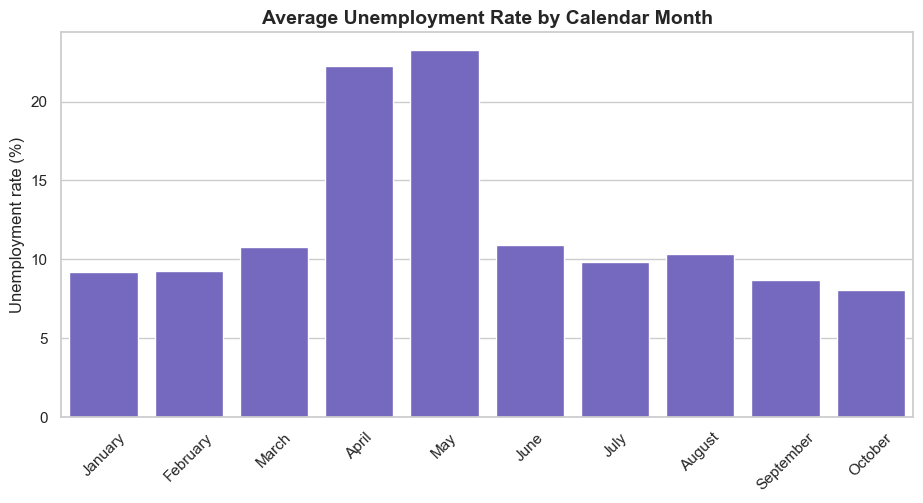

In [11]:
month_order = ["January","February","March","April","May","June","July",
               "August","September","October","November","December"]
calendar_month_avg = (
    df.groupby("month_name")["unemployment_rate"].mean()
      .reindex(month_order).dropna().round(2)
)

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(x=calendar_month_avg.index, y=calendar_month_avg.values, color="slateblue", ax=ax)
ax.set_title("Average Unemployment Rate by Calendar Month")
ax.set_xlabel("")
ax.set_ylabel("Unemployment rate (%)")
plt.xticks(rotation=45)
plt.show()

## 4. Time Series: Unemployment Rate Over Time (4 States)

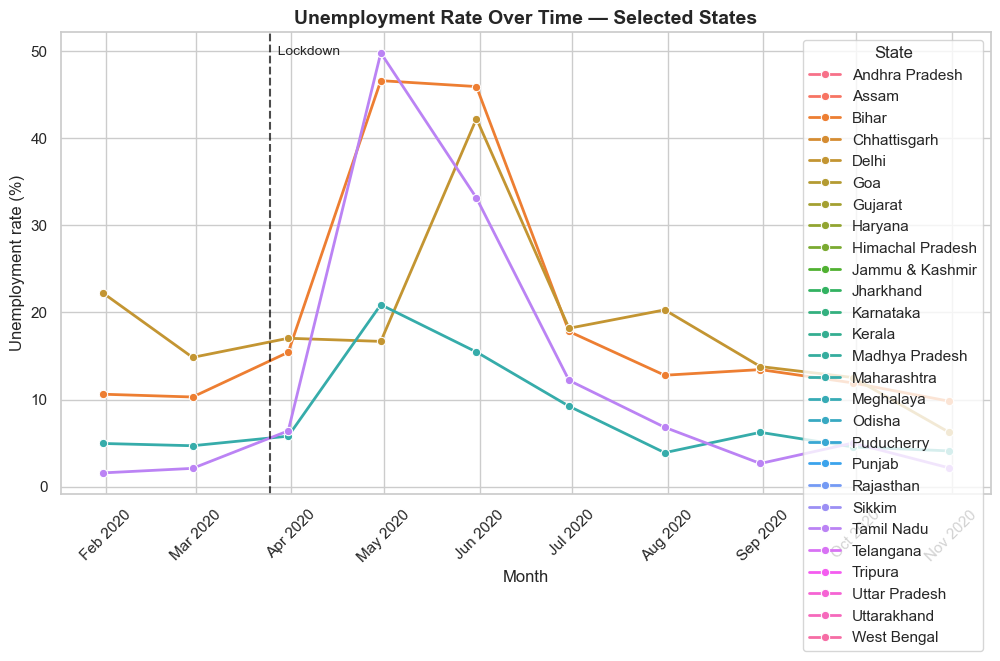

In [13]:
states_to_plot = ["Maharashtra", "Delhi", "Tamil Nadu", "Bihar"]
states_to_plot = [s for s in states_to_plot if s in df["state"].unique()]
subset = df[df["state"].isin(states_to_plot)]

fig, ax = plt.subplots()
sns.lineplot(data=subset, x="date", y="unemployment_rate", hue="state",
             marker="o", linewidth=2, ax=ax)
ax.axvline(LOCKDOWN_DATE, color="black", linestyle="--", alpha=0.7)
ax.text(LOCKDOWN_DATE, ax.get_ylim()[1] * 0.97, "  Lockdown", va="top", fontsize=10)
ax.set_title("Unemployment Rate Over Time — Selected States")
ax.set_xlabel("Month")
ax.set_ylabel("Unemployment rate (%)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
ax.legend(title="State")
plt.show()

In [14]:
peaks = (subset.loc[subset.groupby("state", observed=True)["unemployment_rate"].idxmax(),
                    ["state", "date", "unemployment_rate"]]
         .assign(date=lambda d: d["date"].dt.strftime("%b %Y"))
         .reset_index(drop=True))
peaks

,state,date,unemployment_rate
0,Bihar,Apr 2020,46.64
1,Delhi,May 2020,42.27
2,Maharashtra,Apr 2020,20.90
3,Tamil Nadu,Apr 2020,49.83


**Observation:** All the selected states show the same shape — a relatively stable stretch before March 2020, then a steep spike right after the lockdown line, followed by a partial recovery. What differs is the **size** of the spike and how quickly each state came back. Use the peak-month table above to compare how hard each state was hit.

## 5. Top 10 States by Average Unemployment Rate

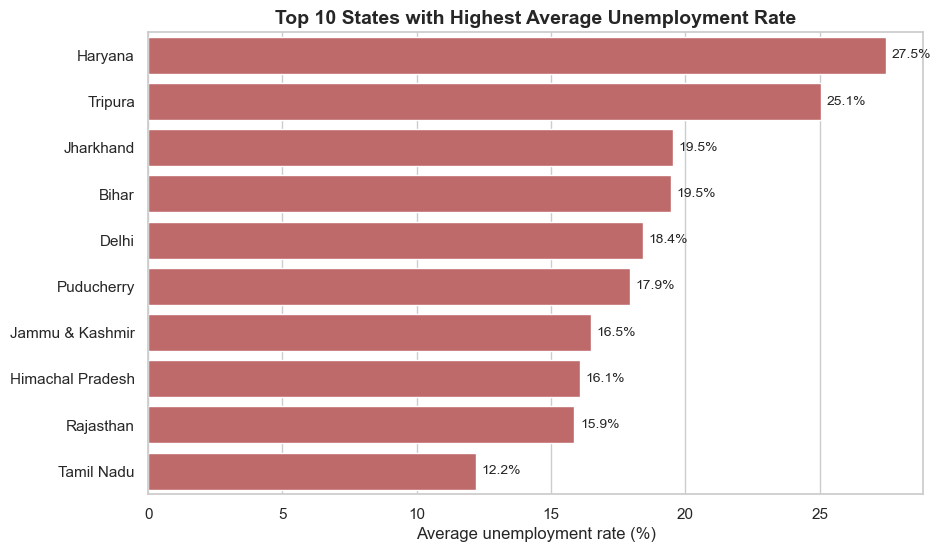

In [15]:
top10 = state_avg["unemployment_rate"].head(10)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top10.values, y=top10.index.astype(str), color="indianred", ax=ax)
ax.set_title("Top 10 States with Highest Average Unemployment Rate")
ax.set_xlabel("Average unemployment rate (%)")
ax.set_ylabel("")
for p in ax.patches:
    ax.annotate(f"{p.get_width():.1f}%", (p.get_width(), p.get_y() + p.get_height() / 2),
                ha="left", va="center", fontsize=10, xytext=(4, 0), textcoords="offset points")
plt.show()

**Observation:** The gap between the top and the 10th state is large, so a few states clearly sit far above the rest. Because this average includes the COVID months, states that were hit hardest by the lockdown rank higher here. Comparing this list with the Pre-COVID ranking in Section 7 shows whether a state had *structurally* high unemployment or was mainly a *pandemic shock* case

## 6. Correlation Heatmap

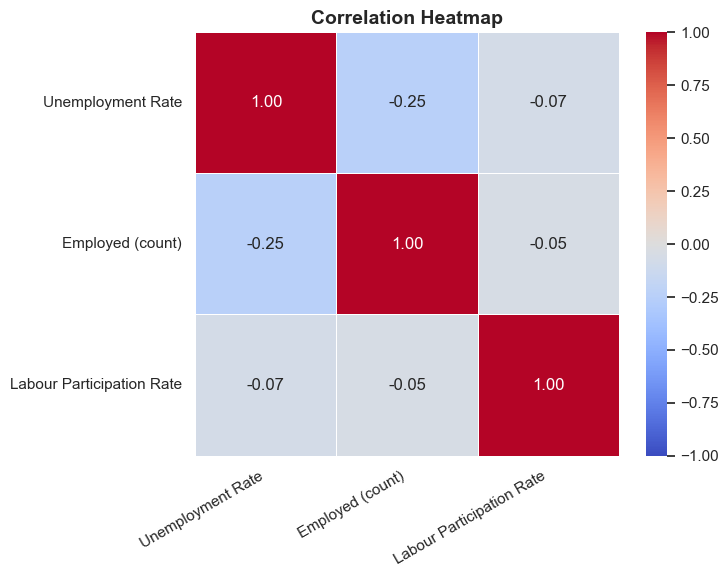

   unemployment_rate vs employed              : -0.25
   unemployment_rate vs labour_participation  : -0.07
            employed vs labour_participation  : -0.05


In [16]:
# Correlation between unemployment, employment (count) and labour participation
corr = df[num_cols].corr()
labels = ["Unemployment Rate", "Employed (count)", "Labour Participation Rate"]

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_title("Correlation Heatmap")
plt.xticks(rotation=30, ha="right")
plt.show()

# Print each pair so the numbers are easy to quote
pairs = [("unemployment_rate", "employed"),
         ("unemployment_rate", "labour_participation"),
         ("employed", "labour_participation")]
for a, b in pairs:
    print(f"{a:>20} vs {b:<22}: {corr.loc[a, b]:+.2f}")

## 7. Pre-COVID vs Post-COVID Comparison

In [17]:
# Split the data at the lockdown date
df["period"] = np.where(df["date"] < LOCKDOWN_DATE, "Pre-COVID", "Post-COVID")
df["period"] = pd.Categorical(df["period"], categories=["Pre-COVID", "Post-COVID"], ordered=True)

print(df.groupby("period", observed=True)["date"].agg(["min", "max", "nunique"])
        .rename(columns={"nunique": "months"}))

period_avg = df.groupby("period", observed=True)[num_cols].mean().round(2)
period_avg

                  min        max  months
period                                  
Pre-COVID  2020-01-31 2020-02-29       2
Post-COVID 2020-03-31 2020-10-31       8


,unemployment_rate,employed,labour_participation
period,,,
Pre-COVID,9.23,15562732.90,44.40
Post-COVID,12.96,13574977.29,41.02


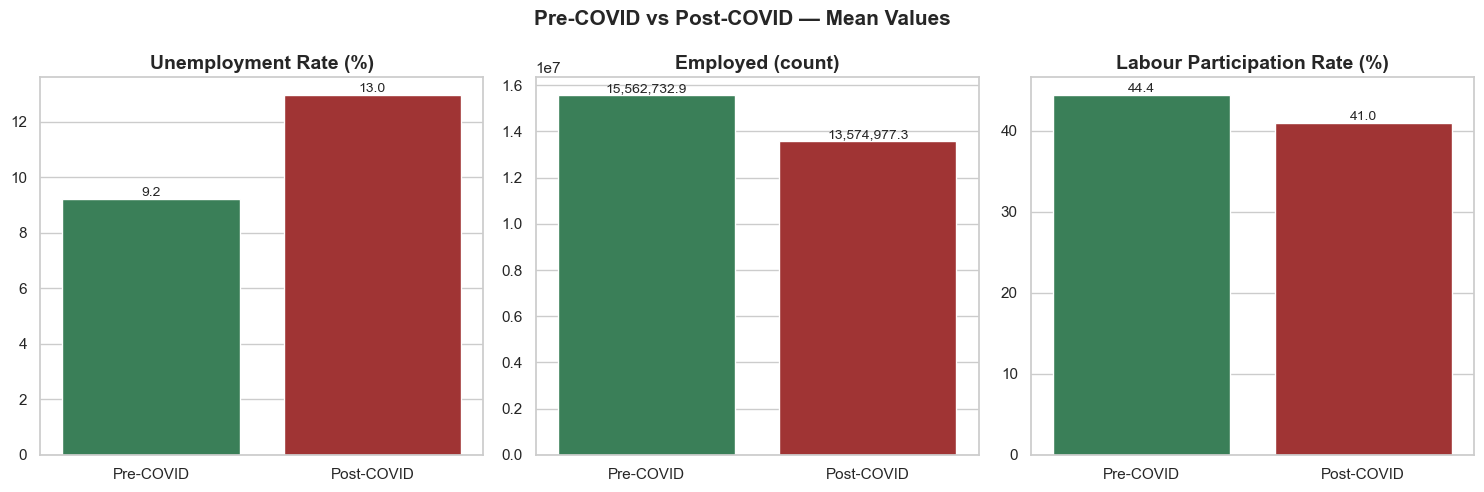

Average unemployment rate: 9.23% (Pre-COVID) -> 12.96% (Post-COVID), a change of +3.73 percentage points (+40%).


In [18]:
# Side-by-side visual of the three metrics before vs after
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
titles = ["Unemployment Rate (%)", "Employed (count)", "Labour Participation Rate (%)"]
colors = ["seagreen", "firebrick"]

for ax, col, title in zip(axes, num_cols, titles):
    sns.barplot(x=period_avg.index.astype(str), y=period_avg[col], palette=colors, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():,.1f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=10)
plt.suptitle("Pre-COVID vs Post-COVID — Mean Values", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

# Quote-ready summary
pre, post = period_avg.loc["Pre-COVID", "unemployment_rate"], period_avg.loc["Post-COVID", "unemployment_rate"]
print(f"Average unemployment rate: {pre:.2f}% (Pre-COVID) -> {post:.2f}% (Post-COVID), "
      f"a change of {post - pre:+.2f} percentage points ({(post / pre - 1) * 100:+.0f}%).")

**Observation:** Comparing the means shows the clear structural break: the average unemployment rate is much higher after the lockdown began, and the other measures shift as well (see the printed summary above for the exact figures). One caveat: the Post-COVID window here is short and dominated by the April–May shock, so it overstates the *long-run* level and understates how much of the damage reversed later.

Top 10 states by increase in unemployment (percentage points):


period,Pre-COVID,Post-COVID,change
state,,,
Puducherry,1.17,22.14,20.96
Tamil Nadu,1.83,14.78,12.95
Bihar,10.45,21.73,11.28
Jharkhand,11.23,21.62,10.39
Goa,5.85,13.75,7.90
Uttarakhand,5.24,12.64,7.40
Karnataka,3.24,8.78,5.54
Haryana,23.06,28.58,5.53
West Bengal,5.93,11.26,5.33


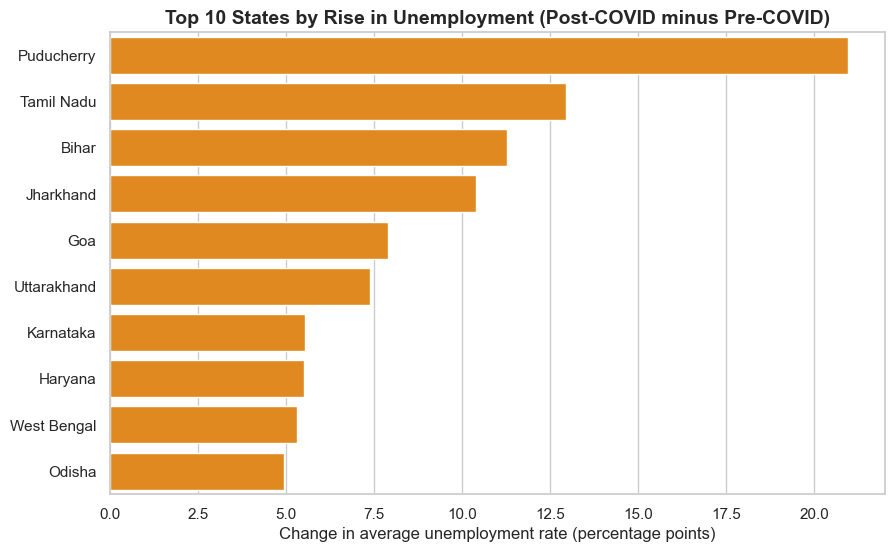

In [19]:
# Which states changed the most? Mean unemployment before vs after, per state
state_period = (df.pivot_table(index="state", columns="period",
                               values="unemployment_rate", aggfunc="mean", observed=True)
                  .assign(change=lambda d: d["Post-COVID"] - d["Pre-COVID"])
                  .sort_values("change", ascending=False)
                  .round(2))

print("Top 10 states by increase in unemployment (percentage points):")
display(state_period.head(10))

top_change = state_period["change"].head(10)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_change.values, y=top_change.index.astype(str), color="darkorange", ax=ax)
ax.set_title("Top 10 States by Rise in Unemployment (Post-COVID minus Pre-COVID)")
ax.set_xlabel("Change in average unemployment rate (percentage points)")
ax.set_ylabel("")
plt.show()

**Observation:** Every state is affected, but the size of the jump varies massively. The states at the top of this chart are those that saw the biggest lockdown shock — which may not be the same states that topped the overall average in Section 5. That distinction matters: a state can have high *baseline* unemployment (a structural issue) or a large *COVID-driven* jump (a shock), and they call for different policy responses.

## 8. Conclusions

- **Temporal:** Unemployment was comparatively stable before March 2020, spiked right after the nationwide lockdown (peaking around April–May 2020), and began easing as restrictions relaxed.
- **Regional:** Unemployment varies hugely across states. Averages over the whole period mix baseline and COVID effects, so the Pre vs Post split gives a cleaner view of who was hit hardest.
- **Relationships:** The correlation heatmap shows how unemployment, employment count and labour participation relate; none of these relationships should be read as causal.
- **COVID impact:** The mean unemployment rate in the Post-COVID period is far above the Pre-COVID period, confirming the lockdown caused a large, broad-based employment shock.

**Limitations**
- The dataset spans only ~1 year, so seasonality can't be separated from the pandemic effect.
- `Estimated Employed` is a headcount, not a rate, and scales with state population.
- Monthly CMIE estimates are survey-based, so small states may be noisy.
- The Pre/Post split uses month-end dates, so the 31 March 2020 observation falls in the Post-COVID group.